<a href="https://colab.research.google.com/github/tustus1022-ui/esaa/blob/main/ESAA_OB_WEEK11_transcription2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<딥러닝 파이토치 교과서> 7장 p.393-417를 필사

## **7.5 LSTM**
RNN의 결정적 단점은 **기울기 소멸 문제**임. 가중치가 업데이트되는 과정에서 1보다 작은 값이 계속 곱해져서 기울기가 사라짐.
이를 해결하기 위해 **LSTM**, **GRU** 같은 확장된 RNN 방식을 사용함. (p.393)

### **7.5.1 LSTM 구조**

**LSTM 순전파**
기울기 소멸 문제를 해결하기 위해 은닉층의 각 뉴런에 **망각 게이트, 입력 게이트, 출력 게이트**라는 새로운 요소를 추가함

**망각 게이트(forget gate)**
과거 정보를 어느 정도 기억할지 결정함
* 과거 정보(h_{t-1})와 현재 데이터(x_t)를 입력받아 **시그모이드**를 취한 뒤, 그 값을 과거 정보에 곱함
* 즉, 이전 상태 정보를 현재 메모리에 반영할지 결정하는 역할
  * 계산한 값이 **1**이면 바로 직전의 정보를 메모리에 **유지**
  * 계산한 값이 **0**이면 **초기화**(과거 정보를 버림)
* 수식: f_t = σ(W_f[h_{t-1}, x_t]),  c_t = f_t · c_{t-1}

**입력 게이트(input gate)**
현재 정보를 기억하기 위해 만들어짐
* 과거 정보와 현재 데이터를 입력받아 **시그모이드와 하이퍼볼릭 탄젠트(tanh)**를 기반으로 현재 정보를 얼마나 보존할지 결정함
* 즉, 현재 메모리에 새로운 정보를 반영할지 결정하는 역할
  * 계산한 값이 **1**이면 입력 x_t가 들어올 수 있도록 허용(open)
  * 계산한 값이 **0**이면 차단
* 수식: i_t = σ(W_i[h_{t-1}, x_t]),  c̃_t = tanh(W_c[h_{t-1}, x_t]),  c_t = c_{t-1} + i_t · c̃_t

**셀(cell)**
* 각 단계의 은닉 노드(hidden node)를 **메모리 셀**이라고 함
* **'총합(sum)'**을 사용해 셀 값을 반영하며, 이것으로 **기울기 소멸 문제가 해결됨**
* 망각 게이트와 입력 게이트의 이전 단계 셀 정보를 계산해서 현재 단계의 **셀 상태(cell state)**를 업데이트함
* 수식: f_t = σ(W_f[h_{t-1}, x_t]),  c_t = f_t · c_{t-1} + i_t · c̃_t

**출력 게이트(output gate)**
과거 정보와 현재 데이터를 사용해 뉴런의 출력을 결정함
* 이전 은닉 상태(hidden state)와 t번째 입력을 고려해 다음 은닉 상태를 계산함. LSTM에서는 **이 은닉 상태가 그 시점의 출력**이 됨
  (이전 은닉 상태 + t번째 입력 = 다음 은닉 상태 = 출력)
* 갱신된 메모리의 출력값을 제어하는 역할
  * 계산한 값이 **1**이면 의미 있는 결과로 최종 출력
  * 계산한 값이 **0**이면 해당 연산을 출력하지 않음
* 수식: o_t = σ(W_o[h_{t-1}, x_t]),  h_t = o_t · tanh(c_{t-1})

**LSTM 역전파**
* LSTM은 **셀을 통해** 역전파를 수행하기 때문에 **'중단 없는 기울기(uninterrupted gradient flow)'**라고도 함
* 최종 오차는 모든 노드에 전파되는데, 이때 셀을 통해 중단 없이 전파됨
* 수식: t_t = tanh(w_hh·h_{t-1} + w_xh·x_t) = tanh(w·[h_{t-1}, x_t])
* 주의: 셀 단위로 오차가 전파된다고 해서 입력 방향으로 오차가 전파되지 않는 것은 아님. **셀 내부적으로는 오차가 입력(x_t)으로도 전파됨**
* LSTM은 RNN과 네트워크 측면에서 어떤 차이가 있는지 비교하면서 학습하면 좋음

### **7.5.2 LSTM 셀 구현**
데이터셋: **MNIST**

**MNIST**
* 얀 르쿤(Yann LeCun) 교수가 만든 데이터셋. 훈련 데이터 6만 개, 검증 데이터 1만 개로 구성됨
* 손으로 쓴 숫자 이미지(0~9, 28×28 픽셀의 고정 크기)

**데이터 전처리**
* 평균 0.5, 표준편차 1.0으로 데이터를 **정규화**함(데이터 분포 조정)
* MNIST 내려받기 파라미터
  * 첫 번째 파라미터: 내려받을 위치
  * transform: 앞에서 정의한 전처리 적용
  * train: True면 훈련용, False면 테스트용 데이터셋
  * download: True면 해당 위치에 파일이 없을 때만 내려받음
* 데이터로더로 MNIST를 메모리로 불러옴. 단, **train_loader, valid_loader, test_loader가 호출될 때** 메모리로 불러온다는 점에 주의
* 변수 설정: batch_size = 100, n_iters = 6000, num_epochs = n_iters / (훈련 데이터 수 / batch_size)

**LSTM 셀 네트워크**
모델 전체가 아니라 LSTM 셀에 집중한 네트워크
* **왜 4 × hidden_size인가?**
  * LSTM에서 중요한 것은 게이트임. 게이트는 **망각, 입력, 셀, 출력** 네 개로 구성됨
  * gates = (입력 × 입력층-은닉층 가중치 + 바이어스) + (은닉 상태 × 은닉층-은닉층 가중치 + 바이어스)
  * 이렇게 계산한 gates를 gates.chunk(4, 1)로 **네 개로 쪼개서** 각각 망각·입력·셀·출력 게이트 변수에 저장함
  * → gates가 네 개로 쪼개지기 때문에 4를 곱한 것임
  * 일반적으로 바이어스에도 4를 곱하지만, 예제에서는 은닉층 뉴런/유닛 개수에만 4를 곱함
* 게이트별 활성화 함수
  * 입력·망각·출력 게이트 → **시그모이드**
  * 셀 게이트 → **tanh**
* LSTM 셀 하나를 통과하면 **셀 상태(c_t)**와 **은닉 상태(h_t)**가 출력됨
  * 셀 상태: 입력, 망각, 셀 게이트로 계산
  * 은닉 상태: 출력 게이트로 계산
* 사용된 함수
  * **torch.chunk(n, dim)**: 텐서를 쪼갤 때 사용. 첫 번째 파라미터는 몇 개로 쪼갤지, 두 번째는 어떤 차원 기준으로 쪼갤지(dim=1이면 열 단위)
  * **uniform()**: 난수 생성(파라미터 초기화에 사용). randint(정수), random(0~1 실수), uniform(범위 내 실수), randrange(간격을 둔 정수)
  * **torch.squeeze()**: 텐서의 차원을 줄일 때 사용. 예) (2×1) 텐서 → (2,) 1차원 벡터
  * **torch.mul()**: 텐서에 곱셈을 할 때 사용

**LSTM 전반적인 네트워크**
* 파라미터: input_dim(입력 특성 수 = 칼럼 개수), hidden_dim(은닉층 뉴런 개수), layer_dim(은닉층 계층 개수)
* 은닉 상태(h0)와 셀 상태(c0)를 (은닉층 계층 개수, 배치 크기, 은닉층 뉴런 개수) 형태의 **0으로 초기화**함
* 시퀀스 길이만큼 LSTM 셀을 반복 적용함. 매번 (hn, cn)을 갱신하고, 마지막 출력을 완전연결층에 통과시킴

**학습 및 성능 확인**
* 손실 함수: CrossEntropyLoss / 옵티마이저: SGD(학습률 0.1)
* seq_dim = 28: 이미지를 (배치, 28, 28) 형태로 바꿔 시퀀스로 입력함
* 500 iteration마다 검증 데이터셋으로 정확도를 계산함 → 최종 검증 정확도 약 **97%**
* **Variable**: 현재 버전에서는 모든 텐서가 자동으로 Variable 성질을 갖기 때문에 사용할 필요가 없음. 학습·연습용이나 이전 버전 코드를 이해하기 위해 사용함
* 모델 학습·예측 코드는 비슷한 패턴으로 진행되므로 **모델의 네트워크와 그 안에서 쓰는 파라미터**에 집중해서 학습하면 좋음
* 테스트 결과: **Test Accuracy 0.98**
* IMDB보다 성능이 훨씬 좋은 이유: IMDB는 사전에 전처리가 되지 않은 데이터셋이고, MNIST는 **사전에 전처리된** 데이터셋이기 때문
  → 전처리가 안 된 데이터셋은 정확도를 높이기 위해 은닉층 개수(또는 뉴런 개수)나 하이퍼파라미터 수정이 필요함

In [1]:
# 라이브러리 호출
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.nn import Parameter   # 파라미터 목록을 가지고 있는 라이브러리(패키지)
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math   # 수학과 관련되어 다양한 함수들과 상수들이 정의되어 있는 라이브러리

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False   # GPU 사용에 필요

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor   # GPU 사용에 필요

torch.manual_seed(125)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(125)

In [2]:
# 데이터 전처리
import torchvision.transforms as transforms

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,)) # 평균을 0.5, 표준편차를 1.0으로 데이터 정규화
])

In [3]:
# 데이터셋 내려받기
from torchvision.datasets import MNIST

download_root = '../chap07/MNIST_DATASET'  ## MNIST를 내려받을 경로

train_dataset = MNIST(download_root, transform=mnist_transform, train=True,
                      download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                     download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                      download=True)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.58MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.25MB/s]


In [4]:
# 데이터셋을 메모리로 가져오기
batch_size = 64
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
valid_loader = DataLoader(dataset=valid_dataset,
                          batch_size=batch_size,
                          shuffle=True)
test_loader = DataLoader(dataset=test_dataset,
                         batch_size=batch_size,
                         shuffle=False)

In [5]:
# 변수 값 지정
batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

In [6]:
# LSTM 셀 네트워크 구축
class LSTMCell(nn.Module):
  def __init__(self, input_size, hidden_size, bias=True):
    super(LSTMCell, self).__init__()
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.bias = bias
    self.x2h = nn.Linear(input_size, 4 * hidden_size, bias=bias)
    self.h2h = nn.Linear(hidden_size, 4 * hidden_size, bias=bias)
    self.reset_parameters()

  def reset_parameters(self): # 모델의 파라미터 초기화
    std = 1.0 / math.sqrt(self.hidden_size)
    for w in self.parameters():
      w.data.uniform_(-std, std)

  def forward(self, x, hidden):
    hx, cx = hidden
    x = x.view(-1, x.size(1))

    gates = self.x2h(x) + self.h2h(hx)
    gates = gates.squeeze()
    ingate, forgetgate, cellgate, outgate = gates.chunk(4,1)

    ingate = F.sigmoid(ingate)  # 입력 게이트에 시그모이드 활성화 함수 적용
    forgetgate = F.sigmoid(forgetgate)  # 망각 게이트에 시그모이드 활성화 함수 적용
    cellgate = F.tanh(cellgate)   # 셀 게이트에 탄젠트 활성화 함수 적용
    outgate = F.sigmoid(outgate)   # 출력 게이트에 시그모이드 활성화 함수 적용

    cy = torch.mul(cx, forgetgate) + torch.mul(ingate, cellgate)
    hy = torch.mul(outgate, F.tanh(cy))
    return(hy, cy)

In [7]:
# LSTM 셀의 전반적인 네트워크
class LSTMModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
    super(LSTMModel, self).__init__()
    self.hidden_dim = hidden_dim   # 은닉층의 뉴런/유닛 개수

    self.layer_dim = layer_dim
    self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
    self.fc = nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    if torch.cuda.is_available(): # GPU 사용 유무 확인
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())  # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 형태를 갖는 은닉 상태를 0으로 초기화
    else:
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    if torch.cuda.is_available(): # GPU 사용 유무 확인
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())  # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 향태를 갖는 셀 상태를 0으로 초기화
    else:
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    outs = []
    cn = c0[0,:,:]  # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 크기를 갖는 셀 상태에 대한 텐서
    hn = h0[0,:,:]   # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 크기를 갖는 은닉 상태에 대한 텐서

    for seq in range(x.size(1)): # LSTM 셀 계층을 반복해 쌓아 올림
      hn, cn = self.lstm(x[:, seq, :], (hn, cn)) # 은닉 상태와 셀 상태를 LSTMCell에 적용한 결과를 또다시 hn, cn에 저장
      outs.append(hn)

    out = outs[-1].squeeze()
    out = self.fc(out)
    return out

In [8]:
# 옵티마이저와 손실 함수 지정
input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available(): # GPU 사용 유무 확인
  model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [9]:
# 모델 학습 및 성능 확인
from torch.autograd import Variable

seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader): # 훈련 데이터셋을 이용한 모델 학습
    if torch.cuda.is_available(): # GPU 사용 확인
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = Variable(labels.cuda())
    else: # GPU를 사용하지 않기 때문에 else 구문이 실행
      images = Variable(images.view(-1, seq_dim, input_dim))
      labels = Variable(labels)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels) # 손실 함수를 이용하여 오차 계산

    if torch.cuda.is_available():
      loss.cuda()

    loss.backward()
    optimizer.step() # 파라미터 업데이트
    loss_list.append(loss.item())
    iter += 1

    if iter % 500 == 0: # 정확도 계산
      correct = 0
      total = 0
      for images, labels in valid_loader: # 검증 데이터셋을 이용한 모델 성능 검증

        if torch.cuda.is_available():
          images = Variable(images.view(-1, seq_dim, input_dim)).cuda()
        else:
          images = Variable(images.view(-1, seq_dim, input_dim))
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1) # 모델을 통과한 결과의 최댓값으로부터 예측 결과 가져오기

        total += labels.size(0)   # 총 레이블 수
        if torch.cuda.is_available():
          correct += (predicted.cpu() == labels.cpu()).sum()
        else:
          correct += (predicted == labels).sum()

      accuracy = 100 * correct / total
      print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))

Iteration: 500. Loss: 2.237457752227783. Accuracy: 21.420000076293945
Iteration: 1000. Loss: 0.9968994855880737. Accuracy: 74.94999694824219
Iteration: 1500. Loss: 0.42673951387405396. Accuracy: 88.13999938964844
Iteration: 2000. Loss: 0.30981600284576416. Accuracy: 93.56999969482422
Iteration: 2500. Loss: 0.055824875831604004. Accuracy: 95.69000244140625
Iteration: 3000. Loss: 0.09873701632022858. Accuracy: 95.58000183105469
Iteration: 3500. Loss: 0.08254366368055344. Accuracy: 96.8499984741211
Iteration: 4000. Loss: 0.03308983892202377. Accuracy: 97.08000183105469
Iteration: 4500. Loss: 0.049307387322187424. Accuracy: 97.08000183105469
Iteration: 5000. Loss: 0.08068697899580002. Accuracy: 96.69999694824219
Iteration: 5500. Loss: 0.12790139019489288. Accuracy: 97.30999755859375
Iteration: 6000. Loss: 0.007093743421137333. Accuracy: 97.66000366210938
Iteration: 6500. Loss: 0.011727365665137768. Accuracy: 97.63999938964844
Iteration: 7000. Loss: 0.008610537275671959. Accuracy: 98.069999

In [10]:
# 테스트 데이터셋을 이용한 모델 예측 성능 확인
def evaluate(model, val_iter):
  corrects, total, total_loss = 0, 0, 0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available(): # GPU 사용 유무 확인
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = labels.cuda()
    else:
      images = Variable(images.view(-1, seq_dim, input_dim)).to(device)
      labels = labels.to(device)
    logit = model(images).to(device)
    loss = F.cross_entropy(logit, labels, reduction="sum")
    _, predicted = torch.max(logit.data, 1) # logit.data 텐서에서 최댓값의 인덱스를 반환
    total += labels.size(0)
    total_loss += loss.item()
    corrects += (predicted == labels).sum()

  avg_loss = total_loss / len(val_iter.dataset)
  avg_accuracy = corrects / total
  return avg_loss, avg_accuracy

In [11]:
# 모델 예측 성능 확인
test_loss, test_acc = evaluate(model, test_loader)
print("Test Loss: %5.2f | Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  0.07 | Test Accuracy:  0.98


### **7.5.3 LSTM 계층 구현**
데이터셋: **스타벅스 주가(SBUX)** → 모델이 주가를 얼마나 잘 예측하는지 확인

**데이터 전처리**
* 칼럼: Date, Open, High, Low, Close, Adj Close, Volume
* **'Date' 칼럼을 인덱스로 사용**
  * 숫자 데이터는 임베딩이 필요 없지만, 단어로 된 데이터셋은 임베딩 과정을 거쳐야 함
  * 날짜 칼럼은 임베딩 처리가 어려운 경우가 많아서 인덱스로 처리하면 편리함
* 'Volume' 칼럼을 정수(int)에서 **실수(float)**로 변경 → 나중에 텐서로 변환할 때 편리함 (astype() 사용)
* 마지막 칼럼(Volume)을 제외한 나머지는 X(훈련), **Volume**은 y(레이블)로 분리함
* 데이터 간 분포가 다르기 때문에 분포를 고르게 맞추는 과정이 필요함
  * **MinMaxScaler()**: 모든 값이 0~1 사이에 있도록 조정 → y에 적용
  * **StandardScaler()**: 평균 0, 분산 1이 되도록 조정 → X에 적용
* 앞의 200개는 훈련, 나머지 53개는 테스트로 분리함
* 데이터셋은 그대로 네트워크에 보낼 수 없고, **네트워크에서 정의한 형태와 크기에 맞게 조정**한 뒤 보내야 함
  * torch.reshape: (200, 5) → **(200, 1, 5)**. LSTM 네트워크의 입력 형태에 맞추기 위함

**LSTM 네트워크**
* 구성: **nn.LSTM 계층**(batch_first=True) → 완전연결층(128) → 출력층, 중간에 ReLU 적용
* 은닉 상태와 셀 상태를 0으로 초기화한 뒤 LSTM 계층에 적용함
* 완전연결층에 적용하기 위해 hn을 1차원으로 형태를 조정함
* 변수: 에포크 1000, 학습률 0.0001, input_size 5(칼럼 수), hidden_size 2, num_layers 1, num_classes 1
* 손실 함수: **MSELoss** / 옵티마이저: **Adam**

**학습 및 예측 결과**
* 에포크가 진행될수록 loss가 감소함(0.102 → 0.00023)
* 오차 위주로 출력했기 때문에 실제로 얼마나 잘 예측했는지는 알기 어려움 → 예측 결과를 **시각화**함
* 전체 데이터에 같은 전처리(정규화, 형태 변경)를 적용해 모델에 넣고, **inverse_transform**으로 정규화를 해제해 본래 값으로 그래프를 출력함
* **axvline()**: 그래프 축을 따라 수직선을 그림(위치, 색상 c, 선 스타일 linestyle 지정). 수평선은 **axhline()**
* 결과: 예측 결과가 만족스럽지 않음
  → 결과가 만족스럽지 않으면 하이퍼파라미터 튜닝도 중요하지만 **모델을 변경**해 보는 것이 좋음(이후 같은 데이터셋으로 GRU와 비교함)

In [12]:
# 라이브러리 호출
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [13]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 19.12 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [14]:
# 데이터셋 가져오기
data = pd.read_csv('080289/chap07/data/SBUX.csv')
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


In [15]:
# 날짜 칼럼을 인덱스로 사용
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True) # 'Date' 칼럼을 인덱스로 사용

In [16]:
# 데이터 형식 변경
data['Volume'] = data['Volume'].astype(float) # 데이터 형식을 변경할 때는 astype()을 사용

In [17]:
# 훈련과 레이블 분리
X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12

In [18]:
# 데이터 분포 조정
ms = MinMaxScaler()  # 데이터의 모든 값이 0~1 사이에 존재하도록 분산 조정
ss = StandardScaler()  # 데이터가 평균 0, 분산 1이 되도록 분산 조정

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]  # 훈련 데이터셋
X_test = X_ss[200:, :]  # 테스트 데이터셋

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


In [19]:
# 데이터셋의 형태 및 크기 조정
X_train_tensors = Variable(torch.Tensor(X_train)) # Variable로 감싸진 텐서는 .backward()가 호출될 때 자동으로 기울기가 계산
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                    1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                  1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("TestingShape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
TestingShape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [20]:
# LSTM 네트워크
class LSTM(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(LSTM, self).__init__()
    self.num_classes = num_classes  # 클래스 개수
    self.num_layers = num_layers  # LSTM 계층의 개수
    self.input_size = input_size  # 입력 크기로 훈련 데이터셋의 칼럼 개수 의미
    self.hidden_size = hidden_size  # 은닉층의 뉴런 개수
    self.seq_length = seq_length  # 시퀀스 길이

    self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                        num_layers=num_layers, batch_first=True) # LSTM 계층
    self.fc_1 = nn.Linear(hidden_size, 128)  # 완전연결층
    self.fc = nn.Linear(128, num_classes) # 출력층
    self.relu = nn.ReLU()

  def forward(self, x):
    h_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))  # 은닉 상태를 0으로 초기화
    c_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))  # 셀 상태를 0으로 초기화
    output, (hn, cn) = self.lstm(x, (h_0, c_0))  # LSTM 계층에 은닉 상태와 셀 상태 적용
    hn = hn.view(-1, self.hidden_size)  # 완전연결층 적용을 위해 데이터의 형태 조정(1차원으로 조정)
    out = self.relu(hn)
    out = self.fc_1(out)
    out = self.relu(out)
    out = self.fc(out)
    return out

In [21]:
# 변수 값 설정
num_epochs = 1000 # 1000번의 에포크
learning_rate = 0.0001 # 학습률을 0.0001로 지정

input_size = 5    # 입력 데이터셋의 칼럼 개수
hidden_size = 2    # 은닉층의 뉴런/유닛 개수
num_layers = 1   # LSTM 계층의 개수

num_classes = 1  # 클래스 개수
model = LSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1]) # 앞에서 정의한 값들을 이용하여 LSTM 모델 학습

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [22]:
# 모델 학습
for epoch in range(num_epochs):
  outputs = model.forward(X_train_tensors_f)  # 전방향 학습
  optimizer.zero_grad()
  loss = criterion(outputs, y_train_tensors)  # 손실함수를 이용한 오차 계산(모델 학습 결과(outputs)와 레이블(y_train_tensors)의 차이 계산)
  loss.backward()  # 기울기 계산

  optimizer.step()  # 오차 업데이트
  if epoch % 100 == 0: # 1000을 100으로 나누어 나머지가 0이면 출력
    print("Epoch: %d, loss: %1.5f" % (epoch,loss.item()))

Epoch: 0, loss: 0.15817
Epoch: 100, loss: 0.05229
Epoch: 200, loss: 0.03819
Epoch: 300, loss: 0.03402
Epoch: 400, loss: 0.02990
Epoch: 500, loss: 0.02604
Epoch: 600, loss: 0.02308
Epoch: 700, loss: 0.02114
Epoch: 800, loss: 0.01998
Epoch: 900, loss: 0.01928


In [23]:
# 모델 예측 결과를 출력하기 위한 데이터 크기 재구성
df_x_ss = ss.transform(data.iloc[:, :-1]) # 데이터 정규화 (분포 조정)
df_y_ms = ms.transform(data.iloc[:, -1:]) # 데이터 정규화

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

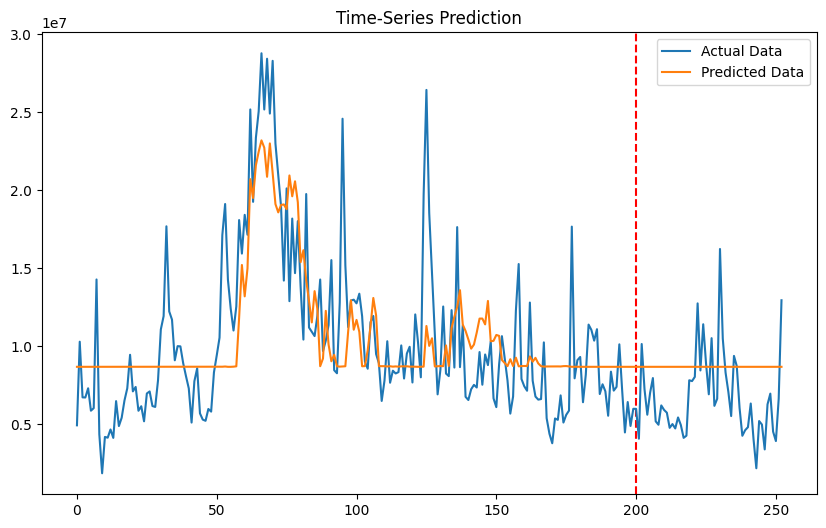

In [24]:
# 모델 예측 결과 출력
train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)  ## 모델 학습을 위해 전처리(정규화)했던 것을 해제해 그래프의 본래 값을 출력
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10,6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()